# PHÂN TÍCH CHẤT LƯỢNG KHÔNG KHÍ (AQI) TẠI HÀ NỘI GIAI ĐOẠN 2022–2025

## Phần 1 — Giới thiệu đồ án

Đồ án sử dụng bốn file CSV trong `dataset/`, ghi nhận theo giờ từ 2022 đến hết tháng 6/2025. Mục tiêu là kiểm tra và tiền xử lý dữ liệu, trả lời bốn câu hỏi nghiên cứu bằng số liệu và biểu đồ, rồi sử dụng dữ liệu đã xử lý để xây dựng hệ thống dự đoán AQI trung bình ngày tiếp theo trong notebook riêng. Năm 2025 chỉ có sáu tháng đầu; không xem đó là một năm đầy đủ. Đơn vị của các chỉ số chất ô nhiễm và nguồn trạm đo chưa được xác minh.

**Bốn câu hỏi nghiên cứu đã được xác nhận:**

1. AQI tại Hà Nội thay đổi giữa các năm 2022–2025 như thế nào khi so sánh cùng khoảng thời gian?
2. AQI tại Hà Nội có xuất hiện mẫu hình theo tháng và mùa nhất quán qua các năm hay không?
3. PM2.5, PM10, CO, NO2, O3 và SO2 có mối liên hệ như thế nào với AQI?
4. Nhiệt độ, độ ẩm, lượng mưa và tốc độ gió có mối liên hệ như thế nào với AQI?

Notebook này chỉ bắt đầu bằng **Giai đoạn 1: Data Understanding**. Các phần làm sạch, EDA và trả lời câu hỏi sẽ được bổ sung sau khi giai đoạn tương ứng được xác nhận. Dữ liệu gốc và notebook mẫu luôn được giữ nguyên.


### Bước 1.1 — Import thư viện

**Mục tiêu:** Chuẩn bị các thư viện phân tích.

**Lý do:** Cần xác nhận công cụ và phiên bản trước khi xử lý.

**Phương pháp:** Import pandas, NumPy, Matplotlib, Seaborn; in phiên bản.

**Kết quả cần quan sát:** Các import thành công và phiên bản được hiển thị.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
print('Python:', sys.version.split()[0])
for name, module in [('pandas', pd), ('NumPy', np), ('Matplotlib', matplotlib), ('Seaborn', sns)]:
    print(f'{name}: {module.__version__}')

Python: 3.14.7
pandas: 3.1.1
NumPy: 2.5.5
Matplotlib: 3.11.2
Seaborn: 0.13.2


### Kết luận bước 1.1

Các thư viện đã import thành công trong Python 3.14.7: pandas 3.1.1, NumPy 2.5.5, Matplotlib 3.11.2 và Seaborn 0.13.2. Chưa phát hiện lỗi import; tiếp tục kiểm tra đường dẫn dữ liệu.

### Bước 1.2 — Kiểm tra đường dẫn

**Mục tiêu:** Xác định bốn file dữ liệu.

**Lý do:** Tránh đọc nhầm hoặc thiếu file.

**Phương pháp:** Dùng pathlib kiểm tra đường dẫn tương đối, tồn tại và kích thước.

**Kết quả cần quan sát:** Cả bốn file tồn tại và khác rỗng.

In [2]:
project_root = Path.cwd().resolve()
if not (project_root / 'dataset').is_dir():
    project_root = project_root.parent
data_dir = project_root / 'dataset'
file_paths = {year: data_dir / f'{year}.csv' for year in (2022, 2023, 2024, 2025)}
for year, path in file_paths.items():
    print(year, path.relative_to(project_root), 'exists=', path.is_file(), 'bytes=', path.stat().st_size if path.is_file() else None)
assert all(path.is_file() and path.stat().st_size > 0 for path in file_paths.values())

2022 dataset\2022.csv exists= True bytes= 1112039
2023 dataset\2023.csv exists= True bytes= 1132940
2024 dataset\2024.csv exists= True bytes= 1138974
2025 dataset\2025.csv exists= True bytes= 564112


### Kết luận bước 1.2

Cả bốn file dataset/2022.csv đến dataset/2025.csv đều tồn tại và có dung lượng lần lượt 1.112.039, 1.132.940, 1.138.974 và 564.112 byte. Đường dẫn tương đối hoạt động từ project; tiếp tục đọc CSV ở chế độ chỉ đọc.

### Bước 1.3 — Đọc bốn CSV

**Mục tiêu:** Đọc bốn CSV vào bộ nhớ.

**Lý do:** Cần DataFrame để khảo sát mà không sửa CSV gốc.

**Phương pháp:** Dùng pandas.read_csv cho từng năm.

**Kết quả cần quan sát:** Bốn DataFrame và số dòng đọc được.

In [3]:
raw_dfs = {year: pd.read_csv(path) for year, path in file_paths.items()}
for year, df in raw_dfs.items():
    print(year, 'DataFrame=', isinstance(df, pd.DataFrame), 'rows=', len(df))

2022 DataFrame= True rows= 8472
2023 DataFrame= True rows= 8736
2024 DataFrame= True rows= 8788
2025 DataFrame= True rows= 4345


### Kết luận bước 1.3

pandas.read_csv đọc thành công cả bốn file thành DataFrame: 2022 có 8.472 dòng, 2023 có 8.736, 2024 có 8.788 và 2025 có 4.345. Chưa biến đổi hay ghi lại dữ liệu gốc; tiếp tục kiểm tra số cột và tổng quy mô.

### Bước 1.4 — Kiểm tra kích thước

**Mục tiêu:** Đếm dòng và cột của mỗi file.

**Lý do:** Quy mô và độ bao phủ có thể khác nhau.

**Phương pháp:** Dùng DataFrame.shape và tính tổng dòng.

**Kết quả cần quan sát:** Bảng kích thước và tổng dòng.

In [4]:
shape_table = pd.DataFrame([{'year': year, 'rows': df.shape[0], 'columns': df.shape[1]} for year, df in raw_dfs.items()])
print(shape_table.to_string(index=False))
print('Total rows:', shape_table['rows'].sum())

 year  rows  columns
 2022  8472       19
 2023  8736       19
 2024  8788       19
 2025  4345       19
Total rows: 30341


### Kết luận bước 1.4

Mỗi file có 19 cột; tổng cộng 30.341 dòng trước xử lý. Số dòng khác nhau giữa các năm cần được đối chiếu với phạm vi thời gian, đặc biệt 2025 chưa đủ năm. Tiếp tục kiểm tra tên cột.

### Bước 1.5 — Kiểm tra tên cột

**Mục tiêu:** So sánh tên cột giữa bốn năm.

**Lý do:** Tên cột lệch sẽ gây lỗi khi ghép.

**Phương pháp:** So danh sách cột của từng năm với 2022.

**Kết quả cần quan sát:** Các tên cột khác biệt được liệt kê.

In [5]:
base = list(raw_dfs[2022].columns)
for year, df in raw_dfs.items():
    print(year, 'same ordered schema=', list(df.columns) == base)
    print('  ', list(df.columns))
    print('  only vs 2022=', sorted(set(df.columns) - set(base)))

2022 same ordered schema= True
   ['Local Time', 'UTC Time', 'City', 'Country Code', 'Timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
  only vs 2022= []
2023 same ordered schema= False
   ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
  only vs 2022= ['Country code', 'timezone']
2024 same ordered schema= False
   ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
  only vs 2022= ['Country code', 'timezone']
2025 same ordered schema= False
   ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', '

### Kết luận bước 1.5

Thứ tự 19 cột tương ứng giữa các năm, nhưng 2023–2025 dùng Country code và timezone trong khi 2022 dùng Country Code và Timezone. Nếu ghép ngay, pandas sẽ tạo cột tách biệt; cần chuẩn hóa tên ở Giai đoạn 2, chưa thực hiện ở đây.

### Bước 1.6 — Kiểm tra kiểu dữ liệu

**Mục tiêu:** Xác định kiểu dữ liệu do pandas suy luận.

**Lý do:** Thời gian và số có thể cần chuyển kiểu trước phân tích.

**Phương pháp:** In DataFrame.dtypes của từng năm.

**Kết quả cần quan sát:** Kiểu của từng cột theo năm.

In [6]:
for year, df in raw_dfs.items():
    print('YEAR', year)
    print(df.dtypes.to_string())

YEAR 2022
Local Time               str
UTC Time                 str
City                     str
Country Code             str
Timezone                 str
AQI                  float64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
Relative Humidity      int64
Temperature          float64
UV Index             float64
Wind Speed           float64
YEAR 2023
Local Time               str
UTC Time                 str
City                     str
Country code             str
timezone                 str
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               

### Kết luận bước 1.6

Pandas đọc Local Time, UTC Time và ba cột định danh ở dạng str, nên thời gian chưa thể dùng trực tiếp cho phép tính chuỗi thời gian. AQI là float64 ở 2022 nhưng int64 ở 2023–2025; các chất ô nhiễm là float64, còn Clouds, Pressure và Relative Humidity là int64. Cần chuyển thời gian và thống nhất kiểu khi tiền xử lý; hiện chưa thay đổi dữ liệu.

### Bước 1.7 — Xem đầu và cuối file

**Mục tiêu:** Xem mẫu ở đầu và cuối mỗi file.

**Lý do:** Ranh giới thời gian cần được đối chiếu với tên năm.

**Phương pháp:** Dùng head(2) và tail(2) cho thời gian, AQI, PM25.

**Kết quả cần quan sát:** Các bản ghi đầu và cuối từng file.

In [7]:
for year, df in raw_dfs.items():
    print('YEAR', year, 'FIRST')
    print(df[['Local Time','UTC Time','AQI','PM25']].head(2).to_string(index=False))
    print('LAST')
    print(df[['Local Time','UTC Time','AQI','PM25']].tail(2).to_string(index=False))

YEAR 2022 FIRST
         Local Time            UTC Time   AQI  PM25
2022-01-13 00:00:00 2022-01-12T17:00:00 180.0 77.67
2022-01-13 01:00:00 2022-01-12T18:00:00 181.0 79.00
LAST
         Local Time            UTC Time   AQI  PM25
2022-12-31 22:00:00 2022-12-31T15:00:00 201.0  94.0
2022-12-31 23:00:00 2022-12-31T16:00:00 164.0  66.0
YEAR 2023 FIRST
         Local Time            UTC Time  AQI  PM25
2023-01-01 00:00:00 2022-12-31T17:00:00  155  59.0
2023-01-01 01:00:00 2022-12-31T18:00:00  171  71.0
LAST
         Local Time            UTC Time  AQI  PM25
2023-12-30 22:00:00 2023-12-30T15:00:00  211 211.0
2023-12-30 23:00:00 2023-12-30T16:00:00  169 169.0
YEAR 2024 FIRST
         Local Time            UTC Time  AQI  PM25
2024-01-01 00:00:00 2023-12-31T17:00:00  208  99.0
2024-01-01 01:00:00 2023-12-31T18:00:00  139  50.0
LAST
         Local Time            UTC Time  AQI  PM25
2024-12-31 22:00:00 2024-12-31T15:00:00  155 155.0
2024-12-31 23:00:00 2024-12-31T16:00:00  264 141.0
YEAR 2025 FIR

### Kết luận bước 1.7

Các dòng đầu/cuối xác nhận 2022 bắt đầu 13/01, 2023 kết thúc 30/12, 2024 bao phủ đến 31/12 và 2025 kết thúc 30/06. Ví dụ đầu 2022 Local Time 00:00 ứng với UTC 17:00 ngày trước. Đây chỉ là kiểm tra mẫu; cần kiểm tra toàn bộ mốc giờ ở bước 1.12.

### Bước 1.8 — Thống kê mô tả

**Mục tiêu:** Mô tả các cột số.

**Lý do:** Cần biết phạm vi và cực trị trước khi xử lý.

**Phương pháp:** Dùng describe với count, min, trung vị, max.

**Kết quả cần quan sát:** Bảng số quan sát và phạm vi theo năm.

In [8]:
numeric_cols = ['AQI','CO','NO2','O3','PM10','PM25','SO2','Clouds','Precipitation','Pressure','Relative Humidity','Temperature','UV Index','Wind Speed']
for year, df in raw_dfs.items():
    print('YEAR', year)
    print(df[numeric_cols].describe().loc[['count','min','50%','max']].round(2).to_string())

YEAR 2022
          AQI      CO     NO2      O3    PM10     PM25     SO2  Clouds  Precipitation  Pressure  Relative Humidity  Temperature  UV Index  Wind Speed
count  8470.0  8398.0  8398.0  8398.0  8470.0  8470.00  8398.0  8472.0         8472.0    8472.0             8472.0       8472.0    8472.0      8472.0
min      21.0    51.4     0.0     0.0     5.0     4.00     0.0     0.0            0.0     992.0               17.0          8.5       0.0         0.0
50%     107.0   176.4    17.3    55.3    49.0    37.67    44.7    75.0            0.0    1010.0               81.0         25.6       0.6         2.0
max     475.0  3002.0   152.0   244.0   579.0   416.00   206.0   100.0           28.0    1029.0              100.0         38.5      11.9         7.2
YEAR 2023
          AQI      CO     NO2      O3    PM10     PM25     SO2  Clouds  Precipitation  Pressure  Relative Humidity  Temperature  UV Index  Wind Speed
count  8736.0  8736.0  8736.0  8736.0  8736.0  8736.00  8736.0  8736.0        87

### Kết luận bước 1.8

Thống kê mô tả xác nhận số quan sát AQI 2022 là 8.470 trên 8.472 dòng, trong khi 2023–2025 đủ theo từng file. Trung vị AQI lần lượt là 107, 112, 105 và 136; đây chỉ là mô tả thô, chưa dùng để so sánh năm vì độ bao phủ khác nhau. Cực trị đáng kiểm tra gồm AQI tối đa 500, CO 15.956,2, O3 700 và PM10 1.103 ở 2024; chưa tự kết luận giá trị sai.

### Bước 1.9 — Kiểm tra giá trị thiếu

**Mục tiêu:** Đếm giá trị thiếu theo cột.

**Lý do:** Không chọn cách điền trước khi biết mức độ và vị trí thiếu.

**Phương pháp:** Dùng isna().sum() và lọc thời gian dòng thiếu.

**Kết quả cần quan sát:** Số ô, tỷ lệ và khoảng thời gian thiếu.

In [9]:
for year, df in raw_dfs.items():
    counts = df.isna().sum()
    missing = counts[counts > 0]
    print('YEAR', year, 'missing cells=', int(counts.sum()))
    print(missing.to_string() if len(missing) else 'none')
    for col in missing.index:
        dates = df.loc[df[col].isna(), 'Local Time']
        print(col, 'pct=', round(100*missing[col]/len(df), 3), 'first=', dates.iloc[0], 'last=', dates.iloc[-1])

YEAR 2022 missing cells= 302
AQI      2
CO      74
NO2     74
O3      74
PM10     2
PM25     2
SO2     74
AQI pct= 0.024 first= 2022-07-01 06:00:00 last= 2022-07-01 07:00:00
CO pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
NO2 pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
O3 pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
PM10 pct= 0.024 first= 2022-07-01 06:00:00 last= 2022-07-01 07:00:00
PM25 pct= 0.024 first= 2022-07-01 06:00:00 last= 2022-07-01 07:00:00
SO2 pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
YEAR 2023 missing cells= 0
none
YEAR 2024 missing cells= 0
none
YEAR 2025 missing cells= 0
none


### Kết luận bước 1.9

Chỉ 2022 có ô thiếu: tổng 302 ô. AQI, PM10 và PM25 thiếu 2 giờ tại 01/07 06:00–07:00 (0,024% mỗi cột); CO, NO2, O3 và SO2 cùng thiếu 74 giờ từ 30/06 05:00 đến 03/07 06:00 (0,873% mỗi cột). Các file 2023–2025 không có ô thiếu. Cụm 74 giờ cần đánh giá riêng ở Giai đoạn 2, không tự điền tiến/lùi.

### Bước 1.10 — Kiểm tra dòng trùng hoàn toàn

**Mục tiêu:** Đếm dòng trùng hoàn toàn.

**Lý do:** Trùng cả dòng khác với trùng thời điểm.

**Phương pháp:** Dùng DataFrame.duplicated().

**Kết quả cần quan sát:** Số dòng trùng từng năm.

In [10]:
for year, df in raw_dfs.items():
    print(year, 'exact duplicate rows=', int(df.duplicated().sum()))

2022 exact duplicate rows= 0
2023 exact duplicate rows= 0
2024 exact duplicate rows= 0
2025 exact duplicate rows= 0


### Kết luận bước 1.10

Không file nào có dòng trùng hoàn toàn theo toàn bộ 19 cột. Kết quả này không loại trừ nhiều bản ghi tại cùng một giờ; tiếp tục kiểm tra Local Time ở bước 1.11.

### Bước 1.11 — Kiểm tra giờ trùng và xung đột

**Mục tiêu:** Tìm mốc giờ có nhiều bản ghi.

**Lý do:** Hai dòng cùng giờ có thể chứa giá trị xung đột.

**Phương pháp:** Dùng duplicated trên Local Time, groupby để so cột.

**Kết quả cần quan sát:** Các mốc giờ lặp và cột khác nhau.

In [11]:
for year, df in raw_dfs.items():
    repeats = df[df['Local Time'].duplicated(keep=False)]
    print('YEAR', year, 'repeated rows=', len(repeats), 'repeated hours=', repeats['Local Time'].nunique())
    for hour, group in repeats.groupby('Local Time', sort=True):
        changed = [c for c in df.columns if group[c].nunique(dropna=False) > 1]
        print(hour, 'changed columns=', changed)
        print(group[['AQI','CO','NO2','O3','PM10','PM25','SO2']].to_string(index=False))

YEAR 2022 repeated rows= 0 repeated hours= 0
YEAR 2023 repeated rows= 0 repeated hours= 0
YEAR 2024 repeated rows= 8 repeated hours= 4
2024-03-01 00:00:00 changed columns= ['O3', 'SO2']
 AQI    CO  NO2   O3  PM10  PM25  SO2
  31 216.0 12.5 27.8   7.5   7.5 38.4
  31 216.0 12.5 33.7   7.5   7.5 35.8
2024-04-01 00:00:00 changed columns= ['SO2']
 AQI    CO  NO2   O3  PM10  PM25  SO2
 150 214.0 18.5 29.2  83.0  55.5 30.3
 150 214.0 18.5 29.2  83.0  55.5 20.0
2024-11-01 00:00:00 changed columns= ['CO', 'NO2', 'O3', 'SO2']
 AQI     CO  NO2   O3  PM10  PM25   SO2
 178 1464.7 20.7 18.6 222.5 178.0  81.0
 178  454.8 29.3 27.3 222.5 178.0 119.7
2024-12-01 00:00:00 changed columns= ['AQI', 'PM10', 'PM25']
 AQI    CO  NO2   O3  PM10  PM25  SO2
 165 164.4 19.3 63.7  71.3 66.67 66.3
 173 164.4 19.3 63.7  81.0 72.33 66.3
YEAR 2025 repeated rows= 2 repeated hours= 1
2025-05-01 00:00:00 changed columns= ['CO', 'O3', 'SO2']
 AQI    CO  NO2   O3  PM10  PM25   SO2
 157 393.7 37.0 32.1  76.3  61.0 288.0
 1

### Kết luận bước 1.11

2022 và 2023 không có giờ lặp. 2024 có 4 giờ lặp (8 dòng) và 2025 có 1 giờ lặp (2 dòng); cả 5 cặp đều khác nhau ít nhất một cột, nên drop_duplicates trên toàn dòng không xử lý được. Đặc biệt 01/12/2024 00:00 có AQI 165 và 173; các cặp còn lại khác O3, SO2 hoặc CO/NO2. Chưa chọn bản ghi nào; Giai đoạn 2 phải xét từng cặp và ghi ảnh hưởng của quy tắc chọn.

### Bước 1.12 — Kiểm tra phạm vi và tính liên tục thời gian

**Mục tiêu:** Kiểm tra phạm vi và tính liên tục thời gian.

**Lý do:** Khoảng thiếu ảnh hưởng so sánh và dự đoán.

**Phương pháp:** Chuyển thời gian trên biến tạm, đối chiếu date_range và UTC+7.

**Kết quả cần quan sát:** Giờ đầu/cuối, giờ thiếu, thời gian lỗi, sai lệch UTC.

In [12]:
all_hours = []
for year, df in raw_dfs.items():
    local = pd.to_datetime(df['Local Time'], errors='coerce')
    utc = pd.to_datetime(df['UTC Time'], errors='coerce', utc=True)
    local_utc = local.dt.tz_localize('Asia/Ho_Chi_Minh').dt.tz_convert('UTC')
    unique = pd.DatetimeIndex(local.dropna().unique()).sort_values()
    expected = pd.date_range(unique.min(), unique.max(), freq='h')
    missing = expected.difference(unique)
    print(year, 'first=', unique.min(), 'last=', unique.max(), 'unique hours=', len(unique), 'internal missing=', len(missing), 'invalid local=', int(local.isna().sum()), 'UTC mismatch=', int((local_utc != utc).sum()))
    all_hours.extend(unique.tolist())
combined = pd.DatetimeIndex(all_hours).unique().sort_values()
missing_all = pd.date_range(combined.min(), combined.max(), freq='h').difference(combined)
print('COMBINED unique hours=', len(combined), 'internal missing=', len(missing_all), 'first missing=', missing_all.min() if len(missing_all) else None, 'last missing=', missing_all.max() if len(missing_all) else None)

2022 first= 2022-01-13 00:00:00 last= 2022-12-31 23:00:00 unique hours= 8472 internal missing= 0 invalid local= 0 UTC mismatch= 0


2023 first= 2023-01-01 00:00:00 last= 2023-12-30 23:00:00 unique hours= 8736 internal missing= 0 invalid local= 0 UTC mismatch= 0
2024 first= 2024-01-01 00:00:00 last= 2024-12-31 23:00:00 unique hours= 8784 internal missing= 0 invalid local= 0 UTC mismatch= 0
2025 first= 2025-01-01 00:00:00 last= 2025-06-30 23:00:00 unique hours= 4344 internal missing= 0 invalid local= 0 UTC mismatch= 0
COMBINED unique hours= 30336 internal missing= 24 first missing= 2023-12-31 00:00:00 last missing= 2023-12-31 23:00:00


### Kết luận bước 1.12

Không có thời gian địa phương không đọc được hoặc sai lệch giữa Local Time và UTC Time ở bất kỳ năm nào. Trong khoảng từng file, không thiếu giờ; số giờ duy nhất là 8.472, 8.736, 8.784 và 4.344. Gộp phạm vi từ 13/01/2022 đến 30/06/2025 có 30.336 giờ duy nhất và thiếu đúng 24 giờ của ngày 31/12/2023. Đầu 2022 và sau 30/06/2025 là ngoài phạm vi file, không được xem là giờ quan sát.

### Bước 1.13 — Kiểm tra giá trị bất thường

**Mục tiêu:** Gắn cờ giá trị bất thường.

**Lý do:** Cực trị cần xem xét trước khi diễn giải.

**Phương pháp:** Đếm AQI ngoài miền, số âm, giá trị 0/500 và tìm cực đại.

**Kết quả cần quan sát:** Số trường hợp và thời điểm cực đại; chưa sửa dữ liệu.

In [13]:
pollutants = ['CO','NO2','O3','PM10','PM25','SO2']
for year, df in raw_dfs.items():
    print(year, 'AQI outside 0..500=', int(((df['AQI'] < 0) | (df['AQI'] > 500)).sum()), 'AQI=500=', int((df['AQI'] == 500).sum()), 'negative pollutants=', int((df[pollutants] < 0).sum().sum()), 'CO=0=', int((df['CO'] == 0).sum()), 'PM25>PM10=', int((df['PM25'] > df['PM10']).sum()))
    for col in ['CO','O3','PM10','SO2']:
        idx = df[col].idxmax()
        print(' ', col, 'max=', df.at[idx,col], 'at', df.at[idx,'Local Time'])

2022 AQI outside 0..500= 0 AQI=500= 0 negative pollutants= 0 CO=0= 0 PM25>PM10= 0
  CO max= 3002.0 at 2022-12-25 10:00:00
  O3 max= 244.0 at 2022-09-14 16:00:00
  PM10 max= 579.0 at 2022-04-08 04:00:00
  SO2 max= 206.0 at 2022-07-06 16:00:00
2023 AQI outside 0..500= 0 AQI=500= 0 negative pollutants= 0 CO=0= 0 PM25>PM10= 4
  CO max= 9160.0 at 2023-11-18 00:00:00
  O3 max= 262.0 at 2023-03-23 16:00:00
  PM10 max= 591.0 at 2023-11-19 20:00:00
  SO2 max= 368.0 at 2023-08-02 10:00:00
2024 AQI outside 0..500= 0 AQI=500= 59 negative pollutants= 0 CO=0= 3 PM25>PM10= 50
  CO max= 15956.2 at 2024-03-06 01:00:00
  O3 max= 700.0 at 2024-08-17 07:00:00
  PM10 max= 1103.0 at 2024-04-11 18:00:00
  SO2 max= 400.0 at 2024-09-15 07:00:00


2025 AQI outside 0..500= 0 AQI=500= 0 negative pollutants= 0 CO=0= 0 PM25>PM10= 15
  CO max= 4133.0 at 2025-06-11 05:00:00
  O3 max= 648.6 at 2025-03-14 00:00:00
  PM10 max= 574.0 at 2025-02-11 15:00:00
  SO2 max= 721.0 at 2025-04-23 13:00:00


### Kết luận bước 1.13

Không có AQI ngoài 0–500 hoặc chỉ số chất ô nhiễm âm trong bốn file. Năm 2024 có 59 dòng AQI = 500 và 3 dòng CO = 0. PM25 lớn hơn PM10 ở 4 dòng năm 2023, 50 dòng năm 2024 và 15 dòng năm 2025. Các cực đại cần xác minh gồm CO 15.956,2, O3 700 và PM10 1.103 ở 2024, SO2 721 ở 2025. Chưa có đơn vị và thông tin trạm để xác định giá trị nào sai; giữ nguyên dữ liệu, chuyển sang đánh giá ở Giai đoạn 2 sau khi được xác nhận.

### Bước 2.1 — Chuẩn hóa tên cột trên bản sao

**Mục tiêu:** Tạo schema thống nhất cho bốn năm.

**Lý do:** Tên khác nhau sẽ tách cột khi ghép; phải chuẩn hóa nhưng không sửa CSV gốc.

**Phương pháp:** Sao chép từng DataFrame và đổi hai cặp tên cột; so sánh danh sách cột.

**Kết quả cần quan sát:** Mỗi bản sao có 19 tên cột giống nhau.

In [14]:
rename_map = {'Country Code':'Country code', 'Timezone':'timezone'}
work_dfs = {year: df.rename(columns=rename_map).copy() for year, df in raw_dfs.items()}
base_columns = list(work_dfs[2022].columns)
for year, df in work_dfs.items():
    print(year, 'columns=', len(df.columns), 'same schema=', list(df.columns)==base_columns, 'rows=',len(df))
print('all columns:', base_columns)
assert all(list(df.columns)==base_columns for df in work_dfs.values())

2022 columns= 19 same schema= True rows= 8472
2023 columns= 19 same schema= True rows= 8736
2024 columns= 19 same schema= True rows= 8788
2025 columns= 19 same schema= True rows= 4345
all columns: ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']


### Kết luận bước 2.1

Sau khi đổi hai tên cột trên bản sao, cả bốn DataFrame có cùng 19 cột và số dòng vẫn là 8.472, 8.736, 8.788, 4.345. Không có giá trị nào bị thay đổi và CSV gốc vẫn nguyên. Tiếp tục chuyển kiểu trên các bản sao để kiểm tra thời gian và số.

### Bước 2.2 — Chuyển kiểu số và chuẩn hóa thời gian trên bản sao

**Mục tiêu:** Tạo kiểu dữ liệu nhất quán để kiểm tra.

**Lý do:** CSV chứa thời gian dạng chuỗi và AQI khác kiểu giữa các năm.

**Phương pháp:** Dùng to_numeric và to_datetime trên bản sao; đếm lỗi chuyển đổi và giá trị số thay đổi.

**Kết quả cần quan sát:** Không phát sinh NaN mới hoặc đổi giá trị số ngoài ý muốn.

In [15]:
numeric_cols = ['AQI','CO','NO2','O3','PM10','PM25','SO2','Clouds','Precipitation','Pressure','Relative Humidity','Temperature','UV Index','Wind Speed']
for year, df in work_dfs.items():
    before = df[numeric_cols].copy()
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce').astype('float64')
    df['Local Time'] = pd.to_datetime(df['Local Time'], errors='coerce')
    df['UTC Time'] = pd.to_datetime(df['UTC Time'], errors='coerce', utc=True)
    new_missing = int(df[numeric_cols].isna().sum().sum() - before.isna().sum().sum())
    changed = int((~np.isclose(df[numeric_cols].to_numpy(dtype=float), before.to_numpy(dtype=float), equal_nan=True)).sum())
    print(year, 'new numeric NaN=',new_missing,'numeric values changed=',changed,'bad local=',int(df['Local Time'].isna().sum()),'bad UTC=',int(df['UTC Time'].isna().sum()),'AQI dtype=',df['AQI'].dtype)
    assert new_missing==0 and changed==0 and df['Local Time'].notna().all() and df['UTC Time'].notna().all()

2022 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64
2023 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64
2024 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64
2025 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64


### Kết luận bước 2.2

Chuyển 14 cột số sang float64 và hai cột thời gian sang kiểu thời gian trên bản sao không tạo thêm NaN, không đổi giá trị số và không có mốc thời gian không đọc được ở cả bốn năm. AQI hiện cùng kiểu float64. Tiếp tục kiểm tra định danh và quan hệ Local Time–UTC Time trước khi xử lý giờ trùng.

### Bước 2.3 — Xác minh định danh và hai cột thời gian

**Mục tiêu:** Kiểm tra mọi dòng thuộc cùng thành phố và UTC khớp giờ địa phương.

**Lý do:** Sai định danh hoặc múi giờ có thể làm sai phân tích theo thời gian.

**Phương pháp:** Đếm giá trị định danh và đối chiếu Local Time quy đổi UTC với UTC Time.

**Kết quả cần quan sát:** Một giá trị nhất quán cho mỗi cột định danh và 0 mốc thời gian không khớp.

In [16]:
for year, df in work_dfs.items():
    local_as_utc = df['Local Time'].dt.tz_localize('Asia/Ho_Chi_Minh').dt.tz_convert('UTC')
    mismatch = int((local_as_utc != df['UTC Time']).sum())
    print(year, 'City=',df['City'].value_counts(dropna=False).to_dict(),'Country code=',df['Country code'].value_counts(dropna=False).to_dict(),'timezone=',df['timezone'].value_counts(dropna=False).to_dict(),'UTC mismatch=',mismatch)
    assert mismatch==0

2022 City= {'Hanoi': 8472} Country code= {'VN': 8472} timezone= {'Asia/Ho_Chi_Minh': 8472} UTC mismatch= 0
2023 City= {'Hanoi': 8736} Country code= {'VN': 8736} timezone= {'Asia/Ho_Chi_Minh': 8736} UTC mismatch= 0
2024 City= {'Hanoi': 8788} Country code= {'VN': 8788} timezone= {'Asia/Ho_Chi_Minh': 8788} UTC mismatch= 0
2025 City= {'Hanoi': 4345} Country code= {'VN': 4345} timezone= {'Asia/Ho_Chi_Minh': 4345} UTC mismatch= 0


### Kết luận bước 2.3

Toàn bộ 30.341 dòng có City = Hanoi, Country code = VN và timezone = Asia/Ho_Chi_Minh. Không có dòng nào lệch giữa Local Time quy đổi UTC+7 và UTC Time. Có thể dùng Local Time làm mốc giờ phân tích, nhưng năm cặp giờ trùng vẫn cần quyết định riêng.

### Bước 2.4 — Đối chiếu từng cặp giờ xung đột

**Mục tiêu:** Xác định chính xác cột và giá trị khác nhau của 5 cặp.

**Lý do:** Không thể chọn bản ghi đúng chỉ bằng kiểm tra dòng trùng hoàn toàn.

**Phương pháp:** Nhóm theo Local Time khi giờ xuất hiện hai lần; in từng cặp và cột khác.

**Kết quả cần quan sát:** Danh sách 5 cặp, các chỉ số khác và mức chênh.

In [17]:
conflicts = []
for year, df in work_dfs.items():
    repeated = df[df['Local Time'].duplicated(keep=False)]
    for hour, pair in repeated.groupby('Local Time', sort=True):
        assert len(pair)==2
        a,b = pair.iloc[0],pair.iloc[1]
        different = [c for c in df.columns if not (pd.isna(a[c]) and pd.isna(b[c])) and a[c]!=b[c]]
        print('YEAR',year,'HOUR',hour,'source row numbers=',list(pair.index+2))
        print('different:',[(c,a[c],b[c],round(float(b[c]-a[c]),2) if c in numeric_cols else None) for c in different])
        conflicts.append({'year':year,'hour':hour,'rows':list(pair.index+2),'different':different,'first':a,'last':b})
print('total conflict hours=',len(conflicts))
assert len(conflicts)==5

YEAR 2024 HOUR 2024-03-01 00:00:00 source row numbers= [1442, 1443]
different: [('O3', np.float64(27.8), np.float64(33.7), 5.9), ('SO2', np.float64(38.4), np.float64(35.8), -2.6)]
YEAR 2024 HOUR 2024-04-01 00:00:00 source row numbers= [2187, 2188]
different: [('SO2', np.float64(30.3), np.float64(20.0), -10.3)]
YEAR 2024 HOUR 2024-11-01 00:00:00 source row numbers= [7324, 7325]
different: [('CO', np.float64(1464.7), np.float64(454.8), -1009.9), ('NO2', np.float64(20.7), np.float64(29.3), 8.6), ('O3', np.float64(18.6), np.float64(27.3), 8.7), ('SO2', np.float64(81.0), np.float64(119.7), 38.7)]
YEAR 2024 HOUR 2024-12-01 00:00:00 source row numbers= [8045, 8046]
different: [('AQI', np.float64(165.0), np.float64(173.0), 8.0), ('PM10', np.float64(71.3), np.float64(81.0), 9.7), ('PM25', np.float64(66.67), np.float64(72.33), 5.66)]
YEAR 2025 HOUR 2025-05-01 00:00:00 source row numbers= [2882, 2883]
different: [('CO', np.float64(393.7), np.float64(230.7), -163.0), ('O3', np.float64(32.1), np.fl

### Kết luận bước 2.4

Đã kiểm tra từng cặp: 01/03/2024 khác O3 và SO2; 01/04/2024 khác SO2; 01/11/2024 khác CO, NO2, O3, SO2; 01/12/2024 khác AQI (165 so với 173), PM10, PM25; 01/05/2025 khác CO, O3, SO2. Cả 5 giờ đều có đúng hai dòng, cùng định danh và thời gian nhưng chỉ số xung đột. CSV không có mã trạm hoặc cờ chất lượng để xác định dòng đúng; tiếp tục lượng hóa ảnh hưởng các lựa chọn, chưa loại hay gộp.

### Bước 2.5 — Đánh giá các phương án cho giờ xung đột

**Mục tiêu:** Đo ảnh hưởng của lựa chọn giữ dòng đầu, dòng cuối hoặc trung bình.

**Lý do:** Không có mã trạm hoặc cờ chất lượng để xác định bản ghi nào đúng.

**Phương pháp:** Tính khoảng chênh AQI và từng chất ô nhiễm cho 5 cặp; không áp dụng phương án nào.

**Kết quả cần quan sát:** Các lựa chọn, mức ảnh hưởng và quyết định cần xác nhận.

In [18]:
for item in conflicts:
    a,b = item['first'],item['last']
    print(item['year'],item['hour'],'rows',item['rows'])
    for col in item['different']:
        if col in numeric_cols:
            print(' ',col,'first=',a[col],'last=',b[col],'mean=',round((a[col]+b[col])/2,3),'absolute difference=',round(abs(a[col]-b[col]),3))
print('Options: first/last/mean each yield one hour but are unsupported by source metadata; keep both retains conflicting hours; exclude conflicting hours avoids arbitrary value but loses 5 hours. No option applied.')

2024 2024-03-01 00:00:00 rows [1442, 1443]
  O3 first= 27.8 last= 33.7 mean= 30.75 absolute difference= 5.9
  SO2 first= 38.4 last= 35.8 mean= 37.1 absolute difference= 2.6
2024 2024-04-01 00:00:00 rows [2187, 2188]
  SO2 first= 30.3 last= 20.0 mean= 25.15 absolute difference= 10.3
2024 2024-11-01 00:00:00 rows [7324, 7325]
  CO first= 1464.7 last= 454.8 mean= 959.75 absolute difference= 1009.9
  NO2 first= 20.7 last= 29.3 mean= 25.0 absolute difference= 8.6
  O3 first= 18.6 last= 27.3 mean= 22.95 absolute difference= 8.7
  SO2 first= 81.0 last= 119.7 mean= 100.35 absolute difference= 38.7
2024 2024-12-01 00:00:00 rows [8045, 8046]
  AQI first= 165.0 last= 173.0 mean= 169.0 absolute difference= 8.0
  PM10 first= 71.3 last= 81.0 mean= 76.15 absolute difference= 9.7
  PM25 first= 66.67 last= 72.33 mean= 69.5 absolute difference= 5.66
2025 2025-05-01 00:00:00 rows [2882, 2883]
  CO first= 393.7 last= 230.7 mean= 312.2 absolute difference= 163.0
  O3 first= 32.1 last= 36.7 mean= 34.4 absol

### Kết luận bước 2.5

Lựa chọn dòng đầu/cuối làm AQI tại 01/12/2024 khác 8 điểm (165 so với 173); lấy trung bình cho 169 nhưng không có chứng cứ đó là phép gộp đúng. Ở 01/11/2024, CO của hai dòng chênh 1.009,9; ở 01/05/2025, SO2 chênh 214,3. Giữ cả hai duy trì 5 giờ không duy nhất; bỏ cả cặp mất 5 giờ. Đề xuất cần xác nhận: giữ một mốc giờ cho mỗi cặp, giữ những cột hai dòng thống nhất và đặt NaN chỉ cho cột xung đột, kèm cờ nguồn; cách này không tự chọn giá trị thiếu căn cứ nhưng làm AQI thiếu thêm 1 giờ. Chưa áp dụng phương án nào và dừng tại đây theo yêu cầu xác nhận.

### Bước 2.6 — Giải quyết giờ xung đột và lưu kiểm toán

**Mục tiêu:** Áp dụng quy tắc đã được xác nhận cho đúng 5 cặp.

**Lý do:** Giữ giờ duy nhất mà không tự chọn giá trị bất đồng.

**Phương pháp:** Với từng cặp, giữ giá trị bằng nhau và đặt NaN ở cột khác nhau; ghi từng cột xung đột vào CSV kiểm toán.

**Kết quả cần quan sát:** Năm giờ được giải quyết, 13 dòng kiểm toán có thể truy vết.

In [19]:
resolved_dfs={}
audit_rows=[]
for year, df in work_dfs.items():
    singles=df.loc[~df['Local Time'].duplicated(keep=False)].copy()
    merged_rows=[]
    repeated=df.loc[df['Local Time'].duplicated(keep=False)]
    for hour,pair in repeated.groupby('Local Time',sort=True):
        a,b=pair.iloc[0],pair.iloc[1]
        merged=a.copy()
        for col in df.columns:
            equal=(pd.isna(a[col]) and pd.isna(b[col])) or a[col]==b[col]
            if not equal:
                merged[col]=np.nan
                audit_rows.append({'year':year,'local_time':hour.strftime('%Y-%m-%d %H:%M:%S'),'first_csv_row':int(pair.index[0]+2),'second_csv_row':int(pair.index[1]+2),'column':col,'first_value':a[col],'second_value':b[col],'decision':'set NaN because values conflict','value_after':np.nan})
        merged_rows.append(merged)
    resolved_dfs[year]=pd.concat([singles,pd.DataFrame(merged_rows,columns=df.columns)],ignore_index=True) if merged_rows else singles.reset_index(drop=True)
audit=pd.DataFrame(audit_rows)
audit_path=project_root/'output/tables/duplicate_conflicts_audit.csv'
audit_path.parent.mkdir(parents=True,exist_ok=True)
audit.to_csv(audit_path,index=False)
print('audit path=',audit_path.relative_to(project_root),'rows=',len(audit),'conflict hours=',audit[['year','local_time']].drop_duplicates().shape[0])
print(audit[['year','local_time','column','first_value','second_value','decision','value_after']].to_string(index=False))

audit path= output\tables\duplicate_conflicts_audit.csv rows= 13 conflict hours= 5
 year          local_time column  first_value  second_value                        decision  value_after
 2024 2024-03-01 00:00:00     O3        27.80         33.70 set NaN because values conflict          NaN
 2024 2024-03-01 00:00:00    SO2        38.40         35.80 set NaN because values conflict          NaN
 2024 2024-04-01 00:00:00    SO2        30.30         20.00 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00     CO      1464.70        454.80 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00    NO2        20.70         29.30 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00     O3        18.60         27.30 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00    SO2        81.00        119.70 set NaN because values conflict          NaN
 2024 2024-12-01 00:00:00    AQI       165.00        173.00 set NaN because v

### Kết luận bước 2.6

Đã tạo một dòng cho mỗi giờ xung đột trên bản sao và ghi 13 cột bất đồng của 5 cặp vào bảng kiểm toán, kèm số dòng CSV nguồn, hai giá trị và quyết định đặt NaN. Sau kiểm tra và sửa định dạng, CSV kiểm toán ghi đủ ngày–giờ 00:00:00 cho cả 5 mốc; hai dòng nguồn được truy vết bằng số dòng CSV. Chưa điền 13 ô NaN.

### Bước 2.7 — Xác minh bảo toàn dữ liệu sau xử lý trùng

**Mục tiêu:** Kiểm tra đầy đủ các điều kiện đã xác nhận.

**Lý do:** Một quy tắc đúng phải chỉ tác động đến 5 giờ và 13 ô bất đồng.

**Phương pháp:** So dòng, giờ, ô thiếu, các dòng không xung đột và các cột đồng thuận trong từng cặp; dùng assert.

**Kết quả cần quan sát:** 30.336 dòng, 0 giờ trùng, 13 NaN mới, 302 NaN gốc được bảo toàn.

In [20]:
before_rows=sum(len(df) for df in work_dfs.values())
after_rows=sum(len(df) for df in resolved_dfs.values())
before_missing=sum(int(df.isna().sum().sum()) for df in work_dfs.values())
after_missing=sum(int(df.isna().sum().sum()) for df in resolved_dfs.values())
checks=[]
for year,original in work_dfs.items():
    resolved=resolved_dfs[year]
    original_singles=original.loc[~original['Local Time'].duplicated(keep=False)].set_index('Local Time').sort_index()
    resolved_singles=resolved.set_index('Local Time').loc[original_singles.index].sort_index()
    unchanged=original_singles.equals(resolved_singles)
    same_hours=set(original['Local Time'])==set(resolved['Local Time'])
    no_dups=not resolved['Local Time'].duplicated().any()
    agreeing=True
    for hour,pair in original.loc[original['Local Time'].duplicated(keep=False)].groupby('Local Time'):
        merged=resolved.loc[resolved['Local Time']==hour].iloc[0]
        for col in original.columns:
            a,b=pair.iloc[0][col],pair.iloc[1][col]
            if (pd.isna(a) and pd.isna(b)) or a==b:
                agreeing=agreeing and ((pd.isna(a) and pd.isna(merged[col])) or a==merged[col])
    checks.append((year,unchanged,same_hours,no_dups,agreeing))
print('before rows=',before_rows,'after rows=',after_rows,'before missing=',before_missing,'after missing=',after_missing,'new missing=',after_missing-before_missing)
print('year / unchanged nonconflict / same hours / no duplicates / agreeing values preserved')
for row in checks: print(*row)
print('audit rows=',len(audit),'new NaN by column=',audit['column'].value_counts().to_dict())
assert before_rows==30341 and after_rows==30336 and before_missing==302 and after_missing==315 and len(audit)==13
assert all(all(row[1:]) for row in checks)

before rows= 30341 after rows= 30336 before missing= 302 after missing= 315 new missing= 13
year / unchanged nonconflict / same hours / no duplicates / agreeing values preserved
2022 True True True True
2023 True True True True
2024 True True True True
2025 True True True True
audit rows= 13 new NaN by column= {'SO2': 4, 'O3': 3, 'CO': 2, 'NO2': 1, 'AQI': 1, 'PM10': 1, 'PM25': 1}


### Kết luận bước 2.7

Các kiểm tra đều đạt: dòng giảm 30.341 → 30.336; ô thiếu 302 → 315, đúng 13 ô mới. Số giờ quan sát không đổi, không còn giờ trùng; mọi dòng không xung đột và các cột đồng thuận trong 5 cặp được giữ nguyên. NaN mới gồm SO2 4, O3 3, CO 2, NO2/AQI/PM10/PM25 mỗi cột 1. Cần tiếp tục phân biệt nguồn thiếu và sửa định dạng thời điểm trong audit trước khi hoàn tất.

### Bước 2.8 — Đánh giá riêng các nguồn thiếu

**Mục tiêu:** Phân biệt thiếu gốc, thiếu do xung đột và giờ không có bản ghi.

**Lý do:** Mỗi loại thiếu có ý nghĩa và cách dùng khác nhau.

**Phương pháp:** Đếm ô thiếu theo cột trước/sau, chỉ rõ cụm 74 giờ và hai giờ AQI; đối chiếu khoảng ngày 31/12/2023.

**Kết quả cần quan sát:** 302 ô thiếu gốc, 13 ô mới, 24 giờ hoàn toàn vắng bản ghi; chưa điền.

In [21]:
for year in work_dfs:
    original=work_dfs[year].isna().sum()
    final=resolved_dfs[year].isna().sum()
    changed=(final-original)
    print(year,'original missing=',int(original.sum()),'after=',int(final.sum()),'new=',int(changed.sum()),'new by column=',changed[changed>0].to_dict())
print('2022 CO/NO2/O3/SO2 missing window: 2022-06-30 05:00 through 2022-07-03 06:00 (74 hours each)')
print('2022 AQI/PM10/PM25 missing: 2022-07-01 06:00 and 07:00 (2 hours each)')
print('2023-12-31 has no rows: 24 hours, not 24 NaN cells')
print('Decision: retain all 315 NaN cells; do not fill or invent timestamps at this stage.')

2022 original missing= 302 after= 302 new= 0 new by column= {}
2023 original missing= 0 after= 0 new= 0 new by column= {}


2024 original missing= 0 after= 10 new= 10 new by column= {'AQI': 1, 'CO': 1, 'NO2': 1, 'O3': 2, 'PM10': 1, 'PM25': 1, 'SO2': 3}
2025 original missing= 0 after= 3 new= 3 new by column= {'CO': 1, 'O3': 1, 'SO2': 1}
2022 CO/NO2/O3/SO2 missing window: 2022-06-30 05:00 through 2022-07-03 06:00 (74 hours each)
2022 AQI/PM10/PM25 missing: 2022-07-01 06:00 and 07:00 (2 hours each)
2023-12-31 has no rows: 24 hours, not 24 NaN cells
Decision: retain all 315 NaN cells; do not fill or invent timestamps at this stage.


### Kết luận bước 2.8

302 ô thiếu gốc chỉ ở 2022 vẫn nguyên; 10 ô mới ở 2024 và 3 ô mới ở 2025 đến từ quy tắc xung đột. Cụm 74 giờ thiếu CO/NO2/O3/SO2 và hai giờ thiếu AQI/PM10/PM25 được giữ NaN, không điền giả; ngày 31/12/2023 là 24 giờ hoàn toàn không có dòng, khác với ô NaN. Quyết định giữ 315 ô NaN để các phép tính sau dùng số quan sát hợp lệ và ghi rõ độ bao phủ; dự đoán cần quy tắc ngày đủ giờ riêng.

### Bước 2.9 — Đánh giá ảnh hưởng của NaN xung đột

**Mục tiêu:** Lượng hóa hệ quả cho thống kê ngày, tháng, năm, tương quan và dự đoán.

**Lý do:** Cần biết mức mất thông tin trước khi dùng bảng cho các giai đoạn sau.

**Phương pháp:** Chỉ tính độ nhạy tại ngày AQI xung đột và số cặp hợp lệ bị mất; không trả lời câu hỏi nghiên cứu.

**Kết quả cần quan sát:** Ngày 01/12/2024 còn 23 AQI hợp lệ, các thống kê thay đổi theo phương án.

In [22]:
day=pd.Timestamp('2024-12-01')
source=work_dfs[2024]; cleaned=resolved_dfs[2024]
raw_day=source.loc[source['Local Time'].dt.normalize()==day,'AQI']
clean_day=cleaned.loc[cleaned['Local Time'].dt.normalize()==day,'AQI']
base_sum=clean_day.sum(); count=int(clean_day.notna().sum())
print('2024-12-01 valid AQI after conflict=',count,'observed daily mean=',round(clean_day.mean(),4))
for label,value in [('first',165),('last',173),('pair mean',169)]: print(label,'daily mean if chosen=',round((base_sum+value)/24,4))
print('daily mean range first-to-last=',round(8/24,4),'monthly mean range upper bound=',round(8/(31*24),6),'2024 full-year mean range upper bound=',round(8/(366*24),6))
for year in (2024,2025):
    original=work_dfs[year]; final=resolved_dfs[year]
    for col in ['PM25','PM10','CO','NO2','O3','SO2']:
        before=int(original[['AQI',col]].notna().all(axis=1).sum()); after=int(final[['AQI',col]].notna().all(axis=1).sum())
        if before!=after: print(year,col,'valid AQI pairs before=',before,'after=',after,'change=',after-before)
print('Prediction: 2024-12-01 has 23 observed AQI hours; 2022-07-01 has 22. A daily completeness rule is needed in prediction stage.')

2024-12-01 valid AQI after conflict= 23 observed daily mean= 160.8261
first daily mean if chosen= 161.0
last daily mean if chosen= 161.3333
pair mean daily mean if chosen= 161.1667
daily mean range first-to-last= 0.3333 monthly mean range upper bound= 0.010753 2024 full-year mean range upper bound= 0.000911
2024 PM25 valid AQI pairs before= 8788 after= 8783 change= -5
2024 PM10 valid AQI pairs before= 8788 after= 8783 change= -5
2024 CO valid AQI pairs before= 8788 after= 8782 change= -6
2024 NO2 valid AQI pairs before= 8788 after= 8782 change= -6
2024 O3 valid AQI pairs before= 8788 after= 8781 change= -7
2024 SO2 valid AQI pairs before= 8788 after= 8780 change= -8
2025 PM25 valid AQI pairs before= 4345 after= 4344 change= -1
2025 PM10 valid AQI pairs before= 4345 after= 4344 change= -1
2025 CO valid AQI pairs before= 4345 after= 4343 change= -2
2025 NO2 valid AQI pairs before= 4345 after= 4344 change= -1
2025 O3 valid AQI pairs before= 4345 after= 4343 change= -2
2025 SO2 valid AQI p

### Kết luận bước 2.9

Ngày 01/12/2024 còn 23 AQI hợp lệ, trung bình trên giờ quan sát là 160,8261; nếu tùy ý chọn AQI 165 hoặc 173 thì trung bình ngày thành 161,0000 hoặc 161,3333 (chênh 0,3333). Chênh do hai lựa chọn này ở trung bình tháng 12/2024 là 0,010753 và trung bình cả 2024 là 0,000911, với giả định mẫu số đủ 744/8.784 giờ. Số cặp AQI–chất ô nhiễm hợp lệ giảm do vừa gộp 5 dòng vừa đặt NaN, chẳng hạn SO2 ở 2024 giảm 8 cặp. Dự đoán ngày cần quy tắc đủ giờ: 01/12/2024 có 23 giờ AQI, 01/07/2022 có 22; chưa chọn ngưỡng ở giai đoạn này.

### Bước 2.10 — Đánh giá giá trị cực trị

**Mục tiêu:** Phân biệt giá trị ngoài miền cơ bản và cực trị chưa xác minh.

**Lý do:** Xóa theo IQR sẽ làm mất các giờ ô nhiễm có thể là thật.

**Phương pháp:** Đếm AQI ngoài 0–500, âm, AQI=500, CO=0 và cực đại; giữ nguyên mọi giá trị chưa có chứng cứ sai.

**Kết quả cần quan sát:** Không có phép cắt ngưỡng hoặc loại hàng.

In [23]:
for year,df in resolved_dfs.items():
    print(year,'AQI outside 0..500=',int(((df['AQI']<0)|(df['AQI']>500)).sum()),'AQI=500=',int((df['AQI']==500).sum()),'negative pollutant cells=',int((df[['CO','NO2','O3','PM10','PM25','SO2']]<0).sum().sum()),'CO=0=',int((df['CO']==0).sum()))
    print(' maxima=',df[['CO','NO2','O3','PM10','PM25','SO2']].max().to_dict())
print('Decision: retain all observed non-NaN values; no IQR/Z-score deletion or AQI cap applied.')

2022 AQI outside 0..500= 0 AQI=500= 0 negative pollutant cells= 0 CO=0= 0
 maxima= {'CO': 3002.0, 'NO2': 152.0, 'O3': 244.0, 'PM10': 579.0, 'PM25': 416.0, 'SO2': 206.0}


2023 AQI outside 0..500= 0 AQI=500= 0 negative pollutant cells= 0 CO=0= 0
 maxima= {'CO': 9160.0, 'NO2': 378.0, 'O3': 262.0, 'PM10': 591.0, 'PM25': 446.0, 'SO2': 368.0}
2024 AQI outside 0..500= 0 AQI=500= 59 negative pollutant cells= 0 CO=0= 3
 maxima= {'CO': 15956.2, 'NO2': 318.6, 'O3': 700.0, 'PM10': 1103.0, 'PM25': 417.0, 'SO2': 400.0}
2025 AQI outside 0..500= 0 AQI=500= 0 negative pollutant cells= 0 CO=0= 0
 maxima= {'CO': 4133.0, 'NO2': 357.0, 'O3': 648.6, 'PM10': 574.0, 'PM25': 457.0, 'SO2': 721.0}
Decision: retain all observed non-NaN values; no IQR/Z-score deletion or AQI cap applied.


### Kết luận bước 2.10

Không có AQI ngoài 0–500 hoặc chỉ số chất ô nhiễm âm. Đã giữ nguyên 59 giá trị AQI = 500 và 3 giá trị CO = 0 ở 2024, cùng các cực đại như CO 15.956,2, O3 700, PM10 1.103 ở 2024 và SO2 721 ở 2025. Những giá trị này là cực trị/chưa xác minh, chưa có đơn vị hay nguồn trạm để kết luận là lỗi; không cắt ngưỡng, xóa theo IQR/Z-score hoặc thay đổi bản ghi. Các bước phân tích sau cần xem độ nhạy khi phù hợp.

### Bước 2.11 — Ghép và sắp xếp bốn năm

**Mục tiêu:** Tạo một bảng thống nhất 19 cột, một dòng mỗi giờ được quan sát.

**Lý do:** Các câu hỏi sau cần cùng một nguồn dữ liệu đã ghi rõ quy tắc.

**Phương pháp:** Dùng concat và sort_values theo Local Time; kiểm tra ranh giới, số dòng/cột và trùng giờ.

**Kết quả cần quan sát:** 30.336 dòng, 19 cột, thứ tự thời gian tăng.

In [24]:
cleaned=pd.concat([resolved_dfs[y] for y in (2022,2023,2024,2025)],ignore_index=True)
cleaned=cleaned.sort_values('Local Time',kind='stable').reset_index(drop=True)
print('shape=',cleaned.shape,'first=',cleaned['Local Time'].min(),'last=',cleaned['Local Time'].max(),'duplicate hours=',int(cleaned['Local Time'].duplicated().sum()),'missing cells=',int(cleaned.isna().sum().sum()),'sorted=',bool(cleaned['Local Time'].is_monotonic_increasing))
assert cleaned.shape==(30336,19) and cleaned['Local Time'].is_unique and cleaned['Local Time'].is_monotonic_increasing

shape= (30336, 19) first= 2022-01-13 00:00:00 last= 2025-06-30 23:00:00 duplicate hours= 0 missing cells= 315 sorted= True


### Kết luận bước 2.11

Đã ghép bốn bản sao và sắp tăng theo Local Time: 30.336 dòng × 19 cột, từ 13/01/2022 00:00 đến 30/06/2025 23:00. Không còn giờ trùng; 315 ô NaN được giữ nguyên. Bảng ghép chỉ chứa các giờ quan sát được, chưa tạo giờ 31/12/2023. Tiếp tục đối chiếu đầy đủ trước/sau.

### Bước 2.12 — Đối chiếu chất lượng trước và sau

**Mục tiêu:** Kiểm tra biến đổi thực tế trước khi lưu.

**Lý do:** Cần chứng minh chỉ 5 dòng xung đột bị gộp và 13 ô bị đánh dấu thiếu.

**Phương pháp:** Lập bảng trước/sau về dòng, giờ duy nhất, trùng, ô thiếu, thời gian và cực trị.

**Kết quả cần quan sát:** Các chỉ số khớp quy tắc được xác nhận.

In [25]:
raw_all=pd.concat([work_dfs[y] for y in (2022,2023,2024,2025)],ignore_index=True)
summary=pd.DataFrame({'metric':['rows','unique hours','duplicate hours (extra rows)','missing cells','AQI missing','AQI=500','CO=0'], 'before':[len(raw_all),raw_all['Local Time'].nunique(),len(raw_all)-raw_all['Local Time'].nunique(),int(raw_all.isna().sum().sum()),int(raw_all['AQI'].isna().sum()),int((raw_all['AQI']==500).sum()),int((raw_all['CO']==0).sum())], 'after':[len(cleaned),cleaned['Local Time'].nunique(),len(cleaned)-cleaned['Local Time'].nunique(),int(cleaned.isna().sum().sum()),int(cleaned['AQI'].isna().sum()),int((cleaned['AQI']==500).sum()),int((cleaned['CO']==0).sum())]})
print(summary.to_string(index=False))
print('range before=',raw_all['Local Time'].min(),'to',raw_all['Local Time'].max())
print('range after=',cleaned['Local Time'].min(),'to',cleaned['Local Time'].max())
print('remaining no-record interval: 2023-12-31 00:00 through 23:00; 2022 starts 01-13; 2025 ends 06-30')
assert summary.set_index('metric').loc['rows'].tolist()==[30341,30336] and summary.set_index('metric').loc['missing cells'].tolist()==[302,315]

                      metric  before  after
                        rows   30341  30336
                unique hours   30336  30336
duplicate hours (extra rows)       5      0
               missing cells     302    315
                 AQI missing       2      3
                     AQI=500      59     59
                        CO=0       3      3


range before= 2022-01-13 00:00:00 to 2025-06-30 23:00:00
range after= 2022-01-13 00:00:00 to 2025-06-30 23:00:00
remaining no-record interval: 2023-12-31 00:00 through 23:00; 2022 starts 01-13; 2025 ends 06-30


### Kết luận bước 2.12

Đối chiếu trước/sau: 30.341 → 30.336 dòng, giờ duy nhất giữ 30.336, dòng dư do trùng 5 → 0, ô thiếu 302 → 315, AQI thiếu 2 → 3. AQI = 500 vẫn 59 dòng và CO = 0 vẫn 3 dòng; phạm vi thời gian không đổi. Khoảng không có bản ghi 31/12/2023 vẫn tồn tại; 2022 bắt đầu 13/01 và 2025 kết thúc 30/06. Các thay đổi khớp quy tắc xung đột, CSV kiểm toán đã được kiểm tra lại với giờ 00:00:00 đầy đủ; có thể lưu file mới.

### Bước 2.13 — Lưu dữ liệu đã xử lý

**Mục tiêu:** Cung cấp đầu vào có thể tái lập cho các giai đoạn sau.

**Lý do:** Notebook 2 phải dùng đúng bảng đã kiểm tra thay vì tự làm sạch lại.

**Phương pháp:** Ghi CSV mới vào output/data rồi đọc lại để kiểm tra số dòng, cột, giờ và NaN.

**Kết quả cần quan sát:** File mới có 30.336 dòng, 19 cột, 315 ô thiếu; CSV gốc không bị ghi đè.

In [26]:
out_path=project_root/'output/data/aqi_hanoi_cleaned.csv'
out_path.parent.mkdir(parents=True,exist_ok=True)
cleaned.to_csv(out_path,index=False)
reloaded=pd.read_csv(out_path)
print('saved=',out_path.relative_to(project_root),'bytes=',out_path.stat().st_size,'shape=',reloaded.shape,'missing=',int(reloaded.isna().sum().sum()),'unique hours=',reloaded['Local Time'].nunique())
assert reloaded.shape==(30336,19) and int(reloaded.isna().sum().sum())==315 and reloaded['Local Time'].nunique()==30336

saved= output\data\aqi_hanoi_cleaned.csv bytes= 4384992 shape= (30336, 19) missing= 315 unique hours= 30336


### Kết luận bước 2.13

Đã lưu output/data/aqi_hanoi_cleaned.csv (4.384.992 byte) và đọc lại: 30.336 dòng × 19 cột, 315 ô thiếu và 30.336 giờ duy nhất. File gốc không bị ghi đè. CSV kiểm toán đã ghi đầy đủ giờ 00:00:00; notebook đã chạy lại từ đầu để xác nhận hai file đầu ra nhất quán.

## Giai đoạn 3 — Exploratory Data Analysis (EDA) tổng quan

Chỉ mô tả dữ liệu đã làm sạch; chưa trả lời bốn câu hỏi nghiên cứu. Mọi phép tính bỏ qua NaN theo quy tắc của pandas và nêu số quan sát hợp lệ. Đơn vị các chỉ số chưa được xác minh.

### Bước 3.1 — Thống kê tổng quan

**Mục tiêu:** Khảo sát số quan sát hợp lệ, trung tâm, độ phân tán và phân vị.

**Lý do:** Bảng chung cho biết biến nào thiếu và biến nào có đuôi phân phối dài.

**Phương pháp:** Đọc CSV đã xử lý; dùng agg và quantile cho 14 cột số.

**Kết quả cần quan sát:** Bảng count, mean, median, std, min, p05, p25, p75, p95, max.

In [27]:
eda=pd.read_csv(project_root/'output/data/aqi_hanoi_cleaned.csv',parse_dates=['Local Time','UTC Time'])
variables=['AQI','CO','NO2','O3','PM10','PM25','SO2','Temperature','Relative Humidity','Precipitation','Wind Speed','Pressure','Clouds','UV Index']
summary=eda[variables].agg(['count','mean','median','std','min','max']).T
for q,label in [(0.05,'p05'),(0.25,'p25'),(0.75,'p75'),(0.95,'p95')]:summary[label]=eda[variables].quantile(q)
summary=summary[['count','mean','median','std','min','p05','p25','p75','p95','max']]
print('shape',eda.shape,'range',eda['Local Time'].min(),eda['Local Time'].max())
print(summary.round(2).to_string())

shape (30336, 19) range 2022-01-13 00:00:00 2025-06-30 23:00:00
                     count     mean   median     std    min      p05     p25     p75      p95      max
AQI                30333.0   123.79   112.00   57.71    4.0    54.00    80.0   157.0   228.00    500.0
CO                 30260.0   425.43   181.50  776.59    0.0    10.00   119.6   342.6  1830.02  15956.2
NO2                30261.0    27.67    18.00   30.06    0.0     5.00    11.0    31.7    84.30    378.0
O3                 30259.0    57.66    48.70   44.05    0.0     4.00    25.3    79.3   145.00    700.0
PM10               30333.0    70.28    52.20   72.73    1.0    17.60    33.8    82.7   177.00   1103.0
PM25               30333.0    50.71    39.33   40.63    1.0    13.75    26.0    61.0   130.00    457.0
SO2                30258.0    64.30    55.70   58.36    0.0     4.00    27.7    88.0   146.70    721.0
Temperature        30336.0    24.88    25.70    5.61    7.0    14.80    20.9    28.9    33.30     40.0
Relative 

### Kết luận bước 3.1

File xử lý có 30.336 dòng × 19 cột. AQI hợp lệ 30.333 giờ, trung bình 123,79, trung vị 112, độ lệch chuẩn 57,71; p25=80, p75=157, p95=228 và phạm vi 4–500. Count thấp hơn 30.336 ở các chất ô nhiễm do NaN đã giữ từ Giai đoạn 2; bảy biến thời tiết đều đủ 30.336 giá trị. Trung bình cho biết mức chung nhưng nhạy với giá trị lớn; trung vị và phân vị mô tả vị trí/phần trải của dữ liệu ít bị cực trị chi phối hơn, còn độ lệch chuẩn đo độ phân tán. CO có trung bình 425,43 lớn hơn trung vị 181,50, cần xem phân phối trước khi diễn giải.

### Bước 3.2 — Phân phối AQI

**Mục tiêu:** Quan sát hình dạng phân phối và giá trị AQI cao.

**Lý do:** Trung bình có thể bị ảnh hưởng bởi đuôi phải và cực trị.

**Phương pháp:** Tính skew, phân vị, số AQI >=300; vẽ histogram và boxplot trên cùng tập hợp lệ.

**Kết quả cần quan sát:** Biểu đồ phân phối, trung bình/trung vị và số giá trị lớn.

valid 30333 mean 123.787 median 112.0 std 57.71 skew 1.494 p95 228.0 p99 270.0 AQI>=300 173 AQI=500 59


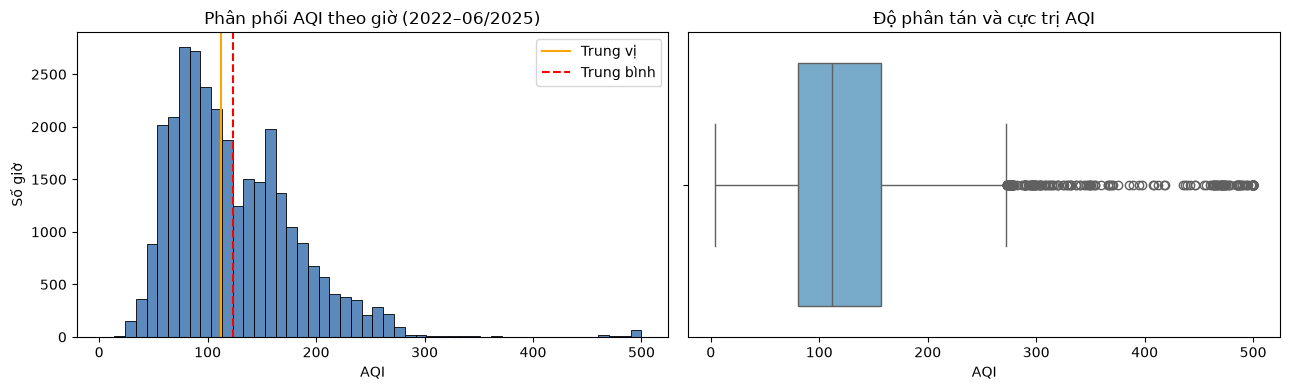

In [28]:
aqi=eda['AQI'].dropna()
print('valid',len(aqi),'mean',round(aqi.mean(),3),'median',round(aqi.median(),3),'std',round(aqi.std(),3),'skew',round(aqi.skew(),3),'p95',aqi.quantile(.95),'p99',aqi.quantile(.99),'AQI>=300',int((aqi>=300).sum()),'AQI=500',int((aqi==500).sum()))
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(aqi,bins=50,ax=axes[0],color='#2563a6');axes[0].axvline(aqi.median(),color='orange',label='Trung vị');axes[0].axvline(aqi.mean(),color='red',linestyle='--',label='Trung bình');axes[0].set(title='Phân phối AQI theo giờ (2022–06/2025)',xlabel='AQI',ylabel='Số giờ');axes[0].legend()
sns.boxplot(x=aqi,ax=axes[1],color='#6baed6');axes[1].set(title='Độ phân tán và cực trị AQI',xlabel='AQI',ylabel='')
fig.tight_layout();fig.savefig(project_root/'output/figures/eda_aqi_distribution.png',dpi=160);plt.show()

### Kết luận bước 3.2

Histogram và boxplot cho thấy AQI tập trung chủ yếu dưới khoảng 200 và có đuôi phải kéo dài; hệ số lệch 1,494, trung bình 123,787 cao hơn trung vị 112. Trong 30.333 giờ hợp lệ có 173 giờ AQI ≥300, gồm 59 giờ AQI=500; p95=228 và p99=270. Các giá trị lớn kéo trung bình lên và xuất hiện như điểm ngoài râu boxplot, nhưng không đủ căn cứ xem là lỗi; chúng được giữ nguyên. Hình: output/figures/eda_aqi_distribution.png. Chưa suy luận xu hướng hoặc nguyên nhân.

### Bước 3.3 — Độ bao phủ theo ngày, tháng và năm

**Mục tiêu:** Phân biệt ngày không có dòng với ngày có dòng nhưng thiếu AQI.

**Lý do:** Độ bao phủ khác nhau có thể làm sai so sánh thời gian.

**Phương pháp:** Nhóm theo ngày; reindex lịch từ 2022-01-01 đến 2025-12-31; tổng hợp theo tháng/năm và vẽ heatmap tỷ lệ giờ có bản ghi.

**Kết quả cần quan sát:** Bảng ngày thiếu/không đủ và heatmap độ bao phủ.

ANNUAL
      days_with_records  days_no_records  recorded_hours  valid_aqi_hours
year                                                                     
2022                353               12            8472             8470
2023                364                1            8736             8736
2024                366                0            8784             8783
2025                181              184            4344             4344
days with 0<valid AQI<24
            recorded_hours  valid_aqi_hours
2022-07-01              24               22
2024-12-01              24               23
2023-12-31 {'recorded_hours': 0, 'valid_aqi_hours': 0}
monthly recorded/valid hours
            recorded_hours  valid_aqi_hours
year month                                 
2022 1                 456              456
     2                 672              672
     3                 744              744
     4                 720              720
     5                 744              744


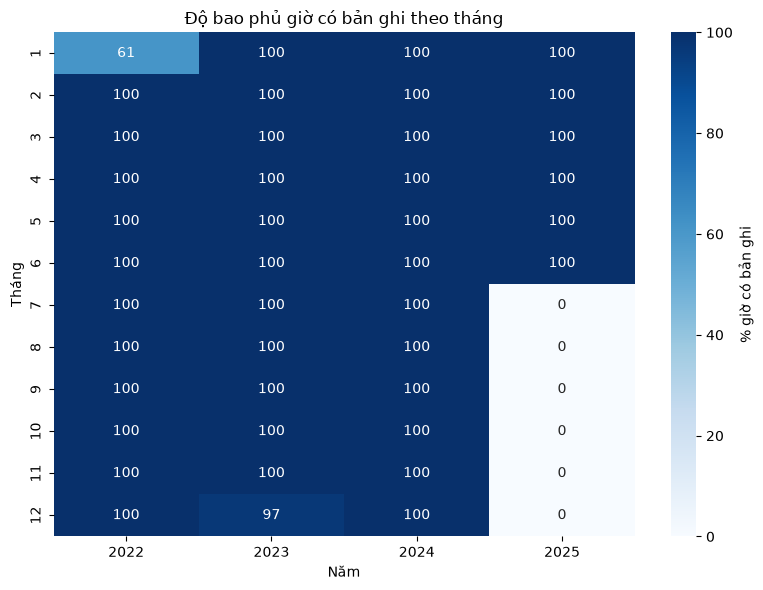

In [29]:
by_day=eda.groupby(eda['Local Time'].dt.normalize()).agg(recorded_hours=('AQI','size'),valid_aqi_hours=('AQI','count'),daily_aqi=('AQI','mean'))
calendar=pd.date_range('2022-01-01','2025-12-31',freq='D')
coverage=by_day.reindex(calendar);coverage[['recorded_hours','valid_aqi_hours']]=coverage[['recorded_hours','valid_aqi_hours']].fillna(0).astype(int)
coverage['year']=coverage.index.year;coverage['month']=coverage.index.month
annual=coverage.groupby('year').agg(days_with_records=('recorded_hours',lambda x:int((x>0).sum())),days_no_records=('recorded_hours',lambda x:int((x==0).sum())),recorded_hours=('recorded_hours','sum'),valid_aqi_hours=('valid_aqi_hours','sum'))
monthly=coverage.groupby(['year','month'])[['recorded_hours','valid_aqi_hours']].sum()
print('ANNUAL');print(annual.to_string())
print('days with 0<valid AQI<24');print(coverage.loc[(coverage['recorded_hours']>0)&(coverage['valid_aqi_hours']<24),['recorded_hours','valid_aqi_hours']].to_string())
print('2023-12-31',coverage.loc['2023-12-31',['recorded_hours','valid_aqi_hours']].to_dict())
print('monthly recorded/valid hours');print(monthly.to_string())
monthly_pct=(monthly['recorded_hours']/pd.MultiIndex.from_tuples(monthly.index).map(lambda ym:pd.Period(f'{ym[0]}-{ym[1]:02d}').days_in_month*24)).unstack(0)*100
fig,ax=plt.subplots(figsize=(8,6));sns.heatmap(monthly_pct,annot=True,fmt='.0f',cmap='Blues',vmin=0,vmax=100,cbar_kws={'label':'% giờ có bản ghi'},ax=ax);ax.set(title='Độ bao phủ giờ có bản ghi theo tháng',xlabel='Năm',ylabel='Tháng');fig.tight_layout();fig.savefig(project_root/'output/figures/eda_coverage.png',dpi=160);plt.show()

### Kết luận bước 3.3

Theo lịch đầy đủ: 2022 có 353 ngày có bản ghi và 12 ngày đầu năm không có; 2023 có 364 ngày có bản ghi, thiếu hẳn 31/12; 2024 đủ 366 ngày; 2025 chỉ có 181 ngày đến 30/06 và không có 184 ngày cuối năm. Số giờ có bản ghi theo năm là 8.472, 8.736, 8.784, 4.344; giờ AQI hợp lệ tương ứng 8.470, 8.736, 8.783, 4.344. Hai ngày có đủ 24 dòng nhưng thiếu AQI là 01/07/2022 (22 giờ hợp lệ) và 01/12/2024 (23 giờ). Heatmap thể hiện tỷ lệ giờ có bản ghi, không phải tỷ lệ AQI hợp lệ: tháng 01/2022 khoảng 61%, tháng 12/2023 khoảng 97%, tháng 07–12/2025 là 0%. Hình: output/figures/eda_coverage.png; các so sánh sau phải kiểm soát độ bao phủ.

### Bước 3.4 — Biến động AQI theo thời gian

**Mục tiêu:** Quan sát tổng quan chuỗi AQI ngày và tháng.

**Lý do:** Tổng hợp phải nêu số giờ hợp lệ và giữ khoảng vắng bản ghi.

**Phương pháp:** Dùng bảng ngày ở bước 3.3, tạo trung bình tháng và hai biểu đồ đường; không suy luận xu hướng dài hạn.

**Kết quả cần quan sát:** Đường ngày/tháng có khoảng trống, bảng số giờ hợp lệ.

daily AQI days 1264 missing days 197
monthly AQI range 68.54 187.09 months 42
first/last monthly rows
            mean_aqi  valid_aqi_hours  recorded_hours
Local Time                                           
2022-01-01    153.15              456             456
2022-02-01    142.49              672             672
2025-05-01    122.92              744             744
2025-06-01    109.26              720             720


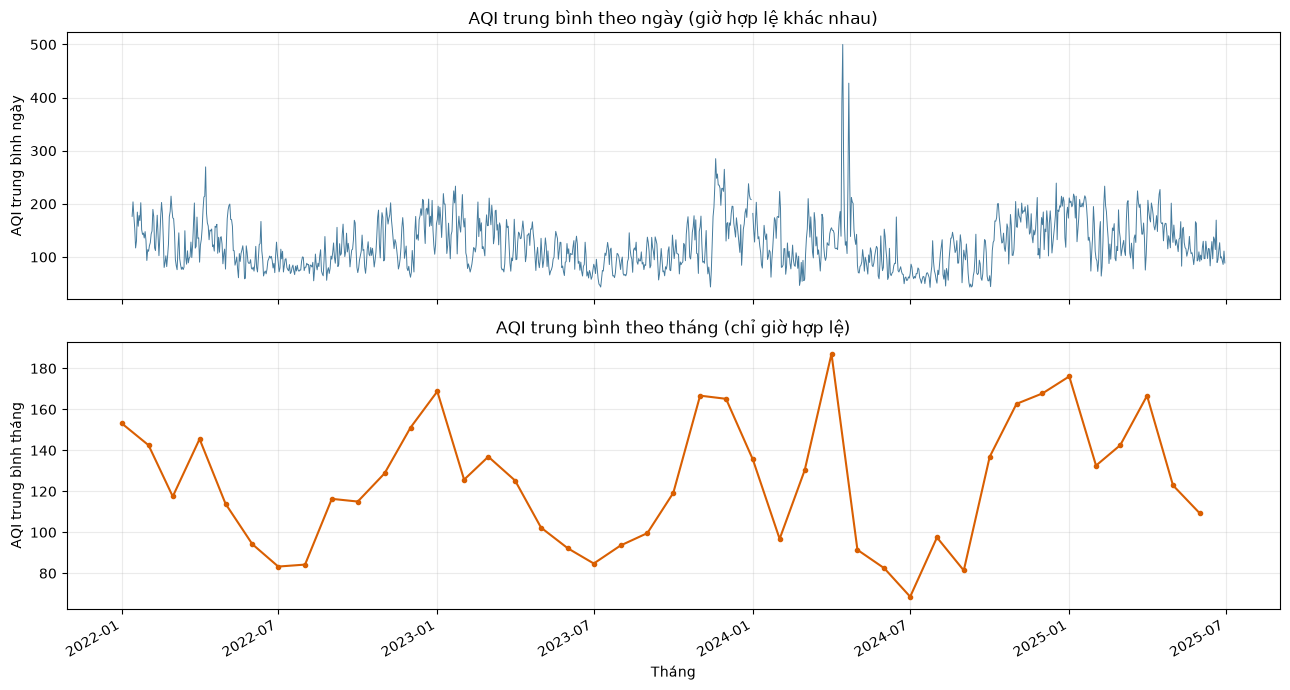

In [30]:
daily_view=coverage[['daily_aqi','valid_aqi_hours']].copy()
monthly_aqi=eda.groupby(eda['Local Time'].dt.to_period('M')).agg(mean_aqi=('AQI','mean'),valid_aqi_hours=('AQI','count'),recorded_hours=('AQI','size'))
monthly_aqi.index=monthly_aqi.index.to_timestamp()
print('daily AQI days',int(daily_view['daily_aqi'].notna().sum()),'missing days',int(daily_view['daily_aqi'].isna().sum()))
print('monthly AQI range',round(monthly_aqi['mean_aqi'].min(),2),round(monthly_aqi['mean_aqi'].max(),2),'months',len(monthly_aqi))
print('first/last monthly rows');print(pd.concat([monthly_aqi.head(2),monthly_aqi.tail(2)]).round(2).to_string())
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(daily_view.index,daily_view['daily_aqi'],color='#457b9d',linewidth=.7);axes[0].set(title='AQI trung bình theo ngày (giờ hợp lệ khác nhau)',ylabel='AQI trung bình ngày',xlabel='Ngày')
axes[1].plot(monthly_aqi.index,monthly_aqi['mean_aqi'],marker='o',markersize=3,color='#d95f02');axes[1].set(title='AQI trung bình theo tháng (chỉ giờ hợp lệ)',ylabel='AQI trung bình tháng',xlabel='Tháng')
for ax in axes:ax.grid(alpha=.25)
fig.autofmt_xdate();fig.tight_layout();fig.savefig(project_root/'output/figures/eda_aqi_over_time.png',dpi=160);plt.show()

### Kết luận bước 3.4

Có 1.264 ngày có AQI trung bình quan sát và 197 ngày trong lịch 2022–2025 không có AQI ngày; 42 tháng có dữ liệu, trung bình tháng trong khoảng 68,54–187,09. Biểu đồ cho thấy dao động đáng kể ở cả thang ngày và tháng; không suy ra xu hướng dài hạn ở bước này. Đỉnh ngày 14/04/2024 được kiểm tra riêng: đủ 24 giờ và cả 24 giá trị AQI đều bằng 500, nên đỉnh 500 trên hình không do thiếu giờ; nguồn gốc các giá trị 500 vẫn chưa xác minh. Bảng tháng kèm valid_aqi_hours, ví dụ 01/2022 chỉ 456 giờ. Hình: output/figures/eda_aqi_over_time.png. Câu hỏi 1–2 sẽ cần so sánh trong khoảng thời gian và độ bao phủ phù hợp.

### Bước 3.5 — Phân phối sáu chất ô nhiễm

**Mục tiêu:** Khảo sát phạm vi và độ lệch của CO, NO2, O3, PM10, PM25, SO2.

**Lý do:** Cực trị có thể nén phần lớn phân phối trên biểu đồ tuyến tính.

**Phương pháp:** Tính count, median, p95, p99, max, skew; vẽ sáu histogram trục đếm log, không gán đơn vị chưa xác minh.

**Kết quả cần quan sát:** Bảng phân phối và hình 6 ô giữ đầy đủ cực trị.

      count  median      p95      p99      max  skew
CO    30260  181.50  1830.02  3643.95  15956.2  5.84
NO2   30261   18.00    84.30   154.00    378.0  3.52
O3    30259   48.70   145.00   192.70    700.0  1.46
PM10  30333   52.20   177.00   305.00   1103.0  6.92
PM25  30333   39.33   130.00   212.00    457.0  2.78
SO2   30258   55.70   146.70   207.70    721.0  4.83


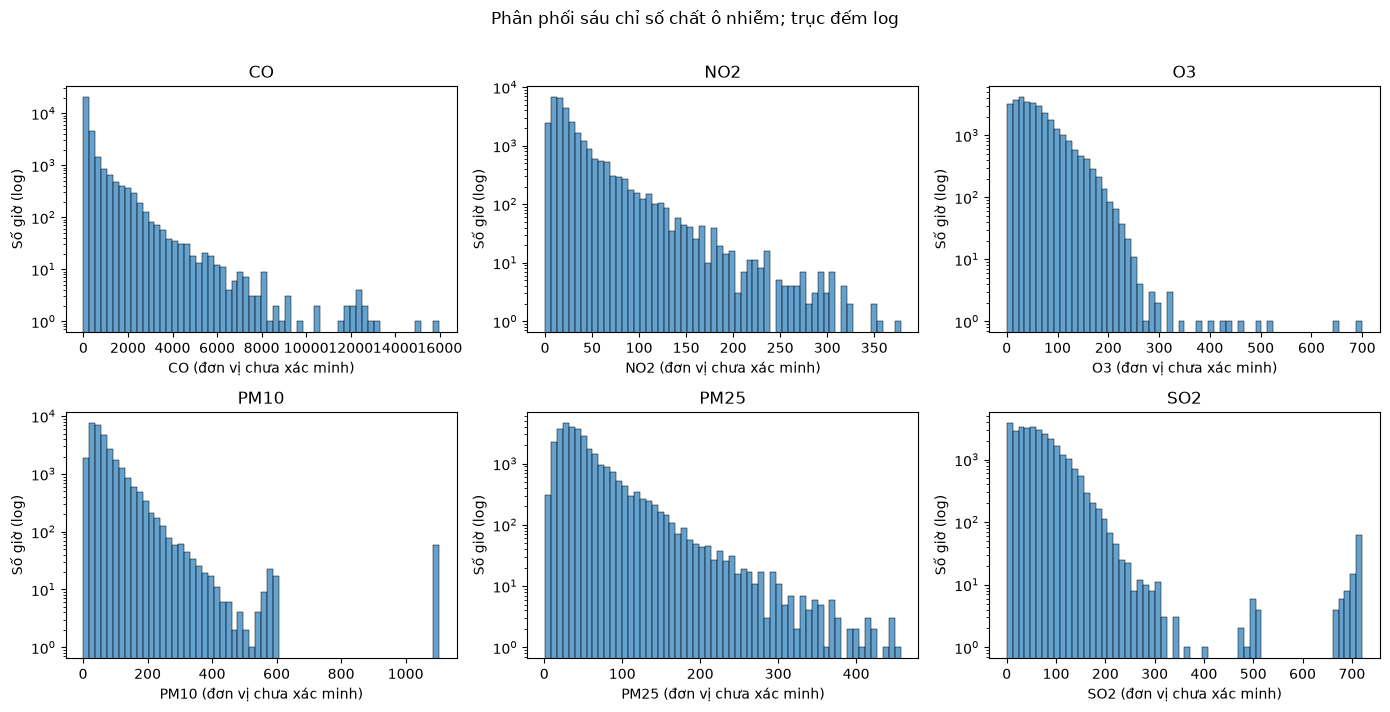

In [31]:
pollutants=['CO','NO2','O3','PM10','PM25','SO2']
poll_stats=pd.DataFrame({'count':eda[pollutants].count(),'median':eda[pollutants].median(),'p95':eda[pollutants].quantile(.95),'p99':eda[pollutants].quantile(.99),'max':eda[pollutants].max(),'skew':eda[pollutants].skew()})
print(poll_stats.round(2).to_string())
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,col in zip(axes.flat,pollutants):
    sns.histplot(eda[col].dropna(),bins=60,ax=ax,color='#3182bd');ax.set_yscale('log');ax.set(title=col,xlabel=f'{col} (đơn vị chưa xác minh)',ylabel='Số giờ (log)')
fig.suptitle('Phân phối sáu chỉ số chất ô nhiễm; trục đếm log',y=1.01);fig.tight_layout();fig.savefig(project_root/'output/figures/eda_pollutants.png',dpi=160,bbox_inches='tight');plt.show()

### Kết luận bước 3.5

Sáu phân phối có đuôi phải (skew dương), rõ ở PM10 6,92 và CO 5,84; trục đếm log giúp thấy cả nhóm phổ biến lẫn giá trị hiếm mà không cắt cực trị. CO có trung vị 181,50, p99=3.643,95, max=15.956,2; PM10 có trung vị 52,20, p99=305, max=1.103. Kiểm tra riêng cụm trên hình cho thấy PM10=1.103 xuất hiện 58 giờ từ 11/04 đến 22/04/2024, SO2≥700 xuất hiện 78 giờ từ 20/04 đến 03/05/2025; đây là cụm cần đánh giá độ nhạy ở Câu hỏi 3, chưa kết luận nguồn gốc hay tính đúng/sai. Số hợp lệ mỗi chất là 30.258–30.333; không gán đơn vị đo. Hình: output/figures/eda_pollutants.png. Chưa tính tương quan với AQI.

### Bước 3.6 — Phân phối các yếu tố thời tiết

**Mục tiêu:** Khảo sát bảy chỉ số thời tiết và số lượng giá trị 0.

**Lý do:** Biến nhiều số 0 hoặc cực trị cần diễn giải khác biến gần đối xứng.

**Phương pháp:** Tính count, median, p95, max, zero count; vẽ histogram bốn biến trọng tâm.

**Kết quả cần quan sát:** Bảng bảy biến và hình 4 ô; chưa phân tích quan hệ với AQI.

                   count     mean  median      p95     max  zero_count
Temperature        30336    24.88    25.7    33.30    40.0           0
Relative Humidity  30336    77.60    82.0    95.00   100.0           0
Precipitation      30336     0.24     0.0     1.25    28.0       25365
Wind Speed         30336     1.78     2.0     3.00    14.9          29
Pressure           30336  1010.08  1010.0  1023.00  1033.0           0
Clouds             30336    71.00    79.0   100.00   100.0        1192
UV Index           30336     1.32     0.6     5.20    12.1       15010


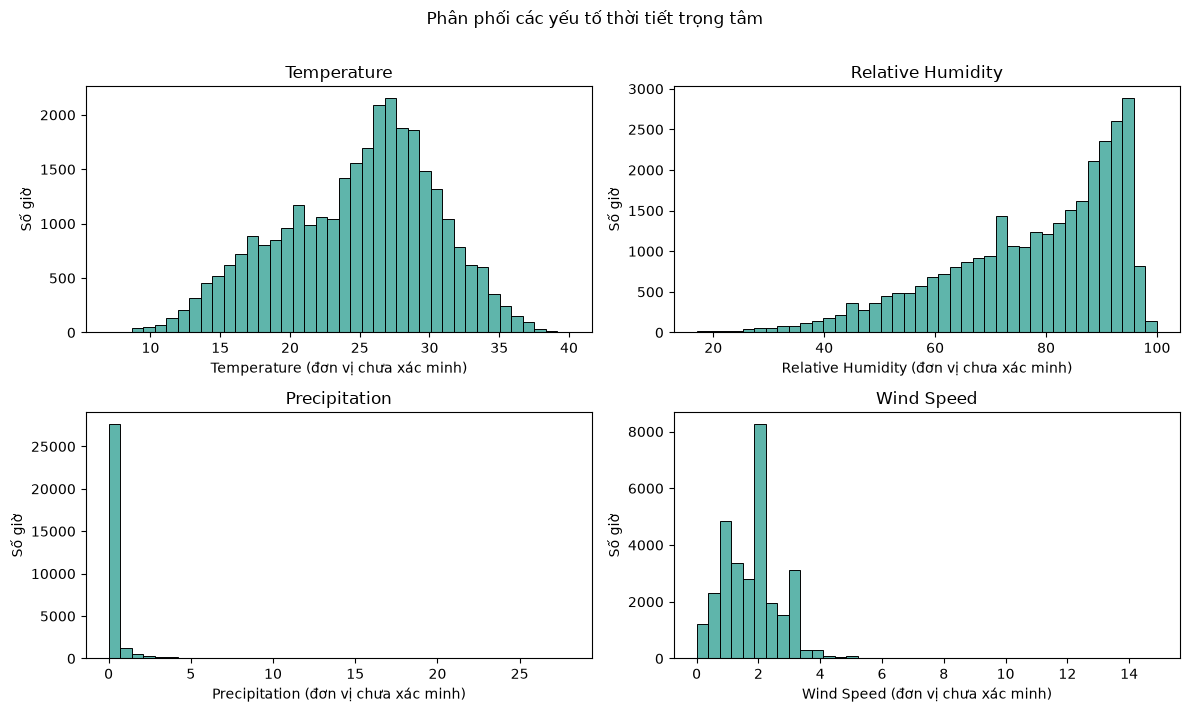

In [32]:
weather=['Temperature','Relative Humidity','Precipitation','Wind Speed','Pressure','Clouds','UV Index']
weather_stats=pd.DataFrame({'count':eda[weather].count(),'mean':eda[weather].mean(),'median':eda[weather].median(),'p95':eda[weather].quantile(.95),'max':eda[weather].max(),'zero_count':(eda[weather]==0).sum()})
print(weather_stats.round(2).to_string())
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,col in zip(axes.flat,['Temperature','Relative Humidity','Precipitation','Wind Speed']):
    sns.histplot(eda[col].dropna(),bins=40,ax=ax,color='#2a9d8f');ax.set(title=col,xlabel=f'{col} (đơn vị chưa xác minh)',ylabel='Số giờ')
fig.suptitle('Phân phối các yếu tố thời tiết trọng tâm',y=1.01);fig.tight_layout();fig.savefig(project_root/'output/figures/eda_weather.png',dpi=160,bbox_inches='tight');plt.show()

### Kết luận bước 3.6

Cả bảy chỉ số thời tiết có 30.336 giá trị hợp lệ. Trong bốn biểu đồ trọng tâm, Temperature trải từ 7 đến 40, trung vị 25,7; Relative Humidity thiên về mức cao với trung vị 82; Wind Speed trung vị 2,0 và cực đại 14,9. Precipitation bằng 0 ở 25.365/30.336 giờ (khoảng 83,6%), nên histogram dồn ở 0; UV Index cũng bằng 0 ở 15.010 giờ. Pressure có trung vị 1.010, Clouds 79 nhưng không cần thêm hình riêng ở EDA tổng quan. Hình: output/figures/eda_weather.png. Chưa kiểm tra mối liên hệ thời tiết–AQI; Câu hỏi 4 sẽ cần chú ý phân phối nhiều số 0 của mưa và đơn vị chưa xác minh.